# Importing Libraries

In [1]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from pathlib import Path
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


# Defining Dataset Path

In [2]:
DATASET_PATH = Path("../dataset/raw/plantvillage_wheat")
CLASSES = ["healthy", "leaf_rust", "stripe_rust", "powdery_mildew"]

print(f"Dataset path : {DATASET_PATH}")
print(f"Classes      : {CLASSES}")
print(f"Path exists  : {DATASET_PATH.exists()}")

Dataset path : ..\dataset\raw\plantvillage_wheat
Classes      : ['healthy', 'leaf_rust', 'stripe_rust', 'powdery_mildew']
Path exists  : True


# Counting Images Per Class

In [3]:
class_counts = {}

for cls in CLASSES:
    folder = DATASET_PATH / cls
    count = len(list(folder.glob("*.jpg")) + list(folder.glob("*.png")))
    class_counts[cls] = count
    print(f"  {cls:<20} -> {count} images")

total = sum(class_counts.values())
print(f"\n  {'TOTAL':<20} -> {total} images")

  healthy              -> 1591 images
  leaf_rust            -> 1256 images
  stripe_rust          -> 1395 images
  powdery_mildew       -> 873 images

  TOTAL                -> 5115 images


# Bar Chart: Images Per Class

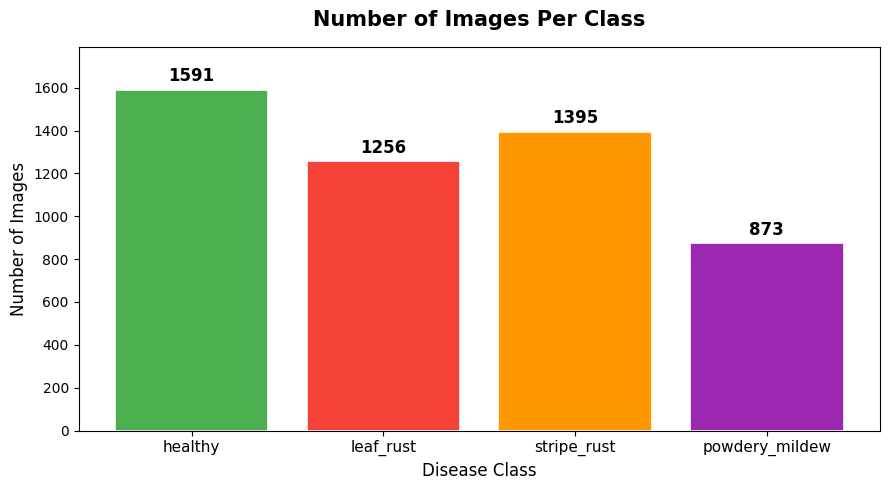

Chart saved to results/class_distribution_bar.png


In [4]:
colors = ["#4CAF50", "#f44336", "#FF9800", "#9C27B0"]

plt.figure(figsize=(9, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(),
               color=colors, edgecolor="white", linewidth=1.2)

for bar, count in zip(bars, class_counts.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             str(count), ha="center", va="bottom",
             fontweight="bold", fontsize=12)

plt.title("Number of Images Per Class", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Disease Class", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.xticks(fontsize=11)
plt.ylim(0, max(class_counts.values()) + 200)
plt.tight_layout()
plt.savefig("../results/class_distribution_bar.png", dpi=150)
plt.show()
print("Chart saved to results/class_distribution_bar.png")

# Pie Chart: Class Distribution

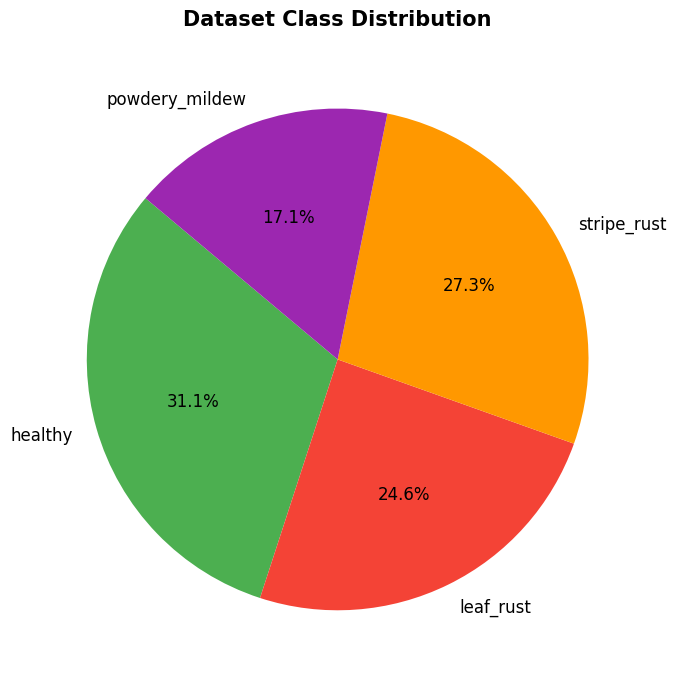

Chart saved to results/class_distribution_pie.png


In [5]:
plt.figure(figsize=(7, 7))
plt.pie(
    class_counts.values(),
    labels=class_counts.keys(),
    colors=colors,
    autopct="%1.1f%%",
    startangle=140,
    textprops={"fontsize": 12}
)
plt.title("Dataset Class Distribution", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("../results/class_distribution_pie.png", dpi=150)
plt.show()
print("Chart saved to results/class_distribution_pie.png")

# Showing Sample Images (3 per class)

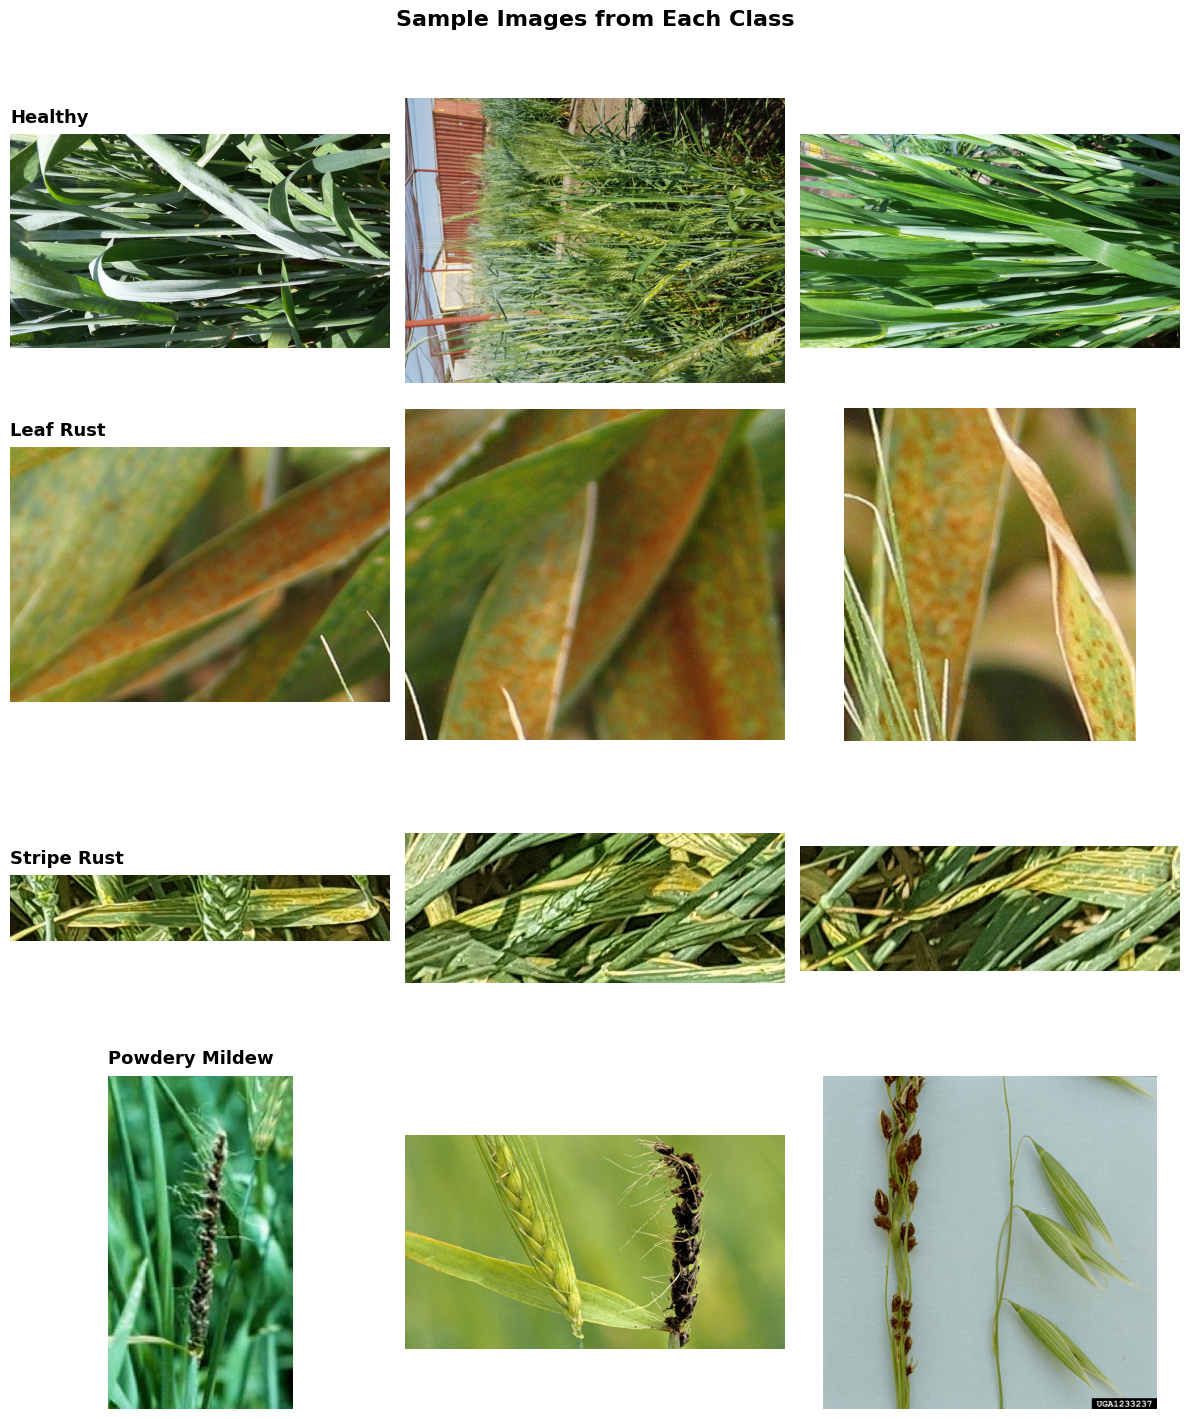

Sample images saved to results/sample_images.png


In [6]:
fig, axes = plt.subplots(4, 3, figsize=(12, 14))
fig.suptitle("Sample Images from Each Class",
             fontsize=16, fontweight="bold", y=1.01)

for row, cls in enumerate(CLASSES):
    folder = DATASET_PATH / cls
    images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))
    samples = images[:3]

    for col, img_path in enumerate(samples):
        img = mpimg.imread(str(img_path))
        axes[row][col].imshow(img)
        axes[row][col].axis("off")
        if col == 0:
            axes[row][col].set_title(
                cls.replace("_", " ").title(),
                fontsize=13, fontweight="bold",
                loc="left", pad=8)

plt.tight_layout()
plt.savefig("../results/sample_images.png", dpi=150, bbox_inches="tight")
plt.show()
print("Sample images saved to results/sample_images.png")

# Checking Image Sizes

In [7]:
print("Checking image sizes in each class...\n")

for cls in CLASSES:
    folder = DATASET_PATH / cls
    images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))
    sizes = set()
    for img_path in images[:50]:   # check first 50 images only
        with Image.open(img_path) as img:
            sizes.add(img.size)
    print(f"  {cls:<20} -> sizes found: {sizes}")

print("\nNote: All images will be resized to 224x224 during preprocessing.")

Checking image sizes in each class...

  healthy              -> sizes found: {(673, 863), (686, 1022), (1801, 367), (1009, 260), (1013, 1008), (768, 1024), (3024, 4032), (1200, 800), (932, 1470), (1176, 601), (758, 906), (375, 305), (753, 626), (1044, 885), (900, 1200), (4032, 3024), (523, 621), (645, 607), (816, 864), (3456, 3456), (1514, 342), (3264, 1836), (384, 288), (1019, 2297)}
  leaf_rust            -> sizes found: {(444, 387), (729, 816), (51, 132), (576, 387), (324, 117), (435, 567), (213, 213), (594, 72), (240, 297), (495, 1344), (228, 570), (456, 168), (414, 1548), (273, 312), (867, 93), (240, 135), (346, 388), (486, 1002), (636, 1221), (759, 645), (462, 114), (540, 924), (267, 894), (1050, 348), (150, 345), (159, 177), (576, 270), (360, 212), (123, 141), (1005, 102), (138, 468), (741, 294), (525, 978), (690, 645), (504, 351), (441, 252), (207, 924), (339, 567), (705, 225), (480, 183), (213, 678), (183, 213), (282, 396), (438, 1095), (339, 576), (513, 1647), (186, 318), (1

# Dataset Summary

In [8]:
print("=" * 50)
print("       DATASET SUMMARY")
print("=" * 50)
print(f"  Total Classes     : {len(CLASSES)}")
print(f"  Total Images      : {total}")
print()

for cls, count in class_counts.items():
    percent = (count / total) * 100
    print(f"  {cls:<20} : {count} images ({percent:.1f}%)")

print()
print(f"  Train set (70%)   : ~{int(total * 0.70)} images")
print(f"  Val   set (15%)   : ~{int(total * 0.15)} images")
print(f"  Test  set (15%)   : ~{int(total * 0.15)} images")
print()
print("  Class Imbalance   : YES — powdery_mildew is smallest")
print("  Fix               : Use class_weight in model training")
print("=" * 50)
print("  Data exploration complete. Proceed to Notebook 02.")
print("=" * 50)

       DATASET SUMMARY
  Total Classes     : 4
  Total Images      : 5115

  healthy              : 1591 images (31.1%)
  leaf_rust            : 1256 images (24.6%)
  stripe_rust          : 1395 images (27.3%)
  powdery_mildew       : 873 images (17.1%)

  Train set (70%)   : ~3580 images
  Val   set (15%)   : ~767 images
  Test  set (15%)   : ~767 images

  Class Imbalance   : YES — powdery_mildew is smallest
  Fix               : Use class_weight in model training
  Data exploration complete. Proceed to Notebook 02.
